# Introduction

---

## Classification in Modern Oncology

Tumor classification is a fundamental component of oncology, guiding prognosis and treatment strategies. Historically based on histopathology, this paradigm has significantly shifted with the understanding that cancer is a disease of profound molecular heterogeneity. Large-scale genomic studies have demonstrated that tumors of the same histological type can be stratified into distinct molecular subtypes, often exhibiting differing clinical outcomes and therapeutic responses ([TCGA Research Network, 2013](https://www.nature.com/articles/ng.2764)). This molecular stratification is a cornerstone of **precision medicine** ([Vogelstein et al., 2013](https://www.science.org/doi/10.1126/science.1235122)).

In prostate cancer, a key clinical challenge is distinguishing indolent from aggressive disease to avoid over-treatment. Standard risk-stratification tools, such as **Prostate-Specific Antigen (PSA)** levels and the **Gleason score**, have known limitations. Transcriptomic data offer a high-resolution molecular profile of a tumor, providing a robust basis for more accurate patient stratification. For instance, a 22-gene transcriptomic signature was validated as an independent predictor of metastatic progression, helping identify patients who require immediate therapy versus those for whom active surveillance may be appropriate ([Erho et al., 2013](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0064942)).

The analysis of high-dimensional transcriptomic data, where the number of features (*p* genes) far exceeds the number of samples (*n*, patients), necessitates specialized computational methods. **Machine learning algorithms** are well-suited for this task. Common methods include Support Vector Machines (SVMs), effective for defining decision boundaries in high-dimensional space, and ensemble methods like Random Forests (RF), which are robust to overfitting and provide feature importance metrics. Such computational approaches are essential for reducing data complexity and generating **clinically actionable classifiers** ([Kourou et al., 2015](https://journalofbigdata.springeropen.com/articles/10.1186/s40537-015-0016-1)).

---

## About this Practical Exercise

This document outlines a comprehensive machine learning workflow for building and evaluating a predictive model from gene expression data. The objective is to **classify patients based on their risk of disease recurrence within a three-year timeframe.**

The analysis is structured as follows:

1.  **Environment Setup and Data Loading:** Set up the python environment in Google Colab, load or install necessary libraries, and read pre-processed gene expression and clinical data.
2.  **Exploratory Data Analysis (EDA):** Perform an initial exploration of data characteristics, including generating a summary table of clinical features and visualizing data structure using unsupervised methods like Principal Component Analysis (PCA).
3.  **Data Partitioning:** Split the dataset into distinct training and testing sets to allow for unbiased model evaluation.
4.  **Feature Selection:** Explore and apply different methods to select a relevant subset of genes, thereby reducing data dimensionality.
5.  **Initial Model Training and Comparison:** Train several classification algorithms on the training data using cross-validation, comparing their performance with metrics like Accuracy and Area Under the ROC Curve (AUC).
6.  **Feature Importance and Refinement:** Examine feature importance from a trained model (Random Forest) to identify the most predictive genes.
7.  **Model Evaluation with Reduced Features:** Retrain models using only the top-ranked features, evaluating their performance on the held-out test set.
---

## Dataset and Clinical Context

The data for this analysis originates from The Cancer Genome Atlas - Prostate Adenocarcinoma (TCGA-PRAD) project. This large-scale effort created a comprehensive catalog of molecular alterations in primary prostate cancer by integrating genomic and transcriptomic data with detailed clinical-pathological annotations for hundreds of patients ([Weinstein et al., 2013](https://doi.org/10.1038/ng.2764)). Gene expression profiles were generated using **RNA-Sequencing (RNA-Seq)**, with raw data processed through standardized bioinformatic pipelines to produce normalized, comparable expression levels across all samples.

This molecular data is paired with key clinical variables critical for prognosis, such as the **ISUP grading** (histological grade), **pathological tumor stage** (extent of tumor spread), and blood **Prostate-Specific Antigen (PSA)** levels. The primary outcome for our predictive task is **Biochemical Recurrence (BCR)**, defined by a rise in PSA levels after definitive treatment and serving as an early indicator of disease relapse ([Freedland & Moul, 2007](https://doi.org/10.1038/sj.pcan.4500923)).

In this practical exercise, we will utilize both the gene expression data and these key clinical variables as features to build a machine learning model aimed at predicting disease recurrence within three years of initial treatment (`recurrence.3y`).

---

## What are we going to do

We will focus on the overall machine learning pipeline, emphasizing methodological choices and their implications.

# Environment Setup and Data Loading

## Load and Inspect Gene Expression Data

**Action:** Run the following code chunk to load the expression data.

In [1]:
import os
import zipfile
import requests
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve, cohen_kappa_score, make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML

In [2]:
!pip install pyreadr
import pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.3/788.3 kB 16.4 MB/s eta 0:00:00


### To use the shared data in this folder:

Go to the shared folder biotrain2026

Select Organize --> Add shortcut

<img src="https://drive.google.com/uc?export=view&id=14UNjWLkh_HR75FFTDEIB4ZyomN3eTyr9" alt="img1" width="80%">

Go to All locations
Select My Drive, then Add

<img src="https://drive.google.com/uc?export=view&id=1_oB11wBHkGzfHoq0KgCjufYEno9AU4JG" alt="img2" width="40%">

Mount your local drive:

In [3]:
from google.colab import drive
import os
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


Change the working directory.

You should change to $\verb|/content/drive/My Drive/EMBL-EBI 2026. Gene expression group/|$

In [4]:
os.chdir('/content/drive/My Drive/Cursos/metagenomica/EMBL-EBI 2026. Gene expression group/')
!ls

Code  Data  Info  References


In [5]:
# load the data
exp = pyreadr.read_r("Data/gene_expresion_prostate_cancer.RDS")[None]

In [6]:
print("Shape: ",exp.shape)
exp.head()

Shape:  (243, 20530)


,ARHGEF10L,HIF3A,RNF17,RNF10,RNF11,RNF13,GTF2IP1,REM1,MTVR2,RTN4RL2,...,TULP2,NPY5R,GNGT2,GNGT1,TULP3,PTRF,BCL6B,GSTK1,SELP,SELS
TCGA-2A-A8VO-01,9.1050,7.1622,0.0000,12.2349,10.9611,10.5777,12.6094,4.9185,0.0000,5.5296,...,1.8713,2.3184,3.4554,0.0,8.9015,12.5682,7.1283,11.0117,8.1436,10.9057
TCGA-2A-A8VT-01,9.6582,4.6591,0.0000,12.1076,11.2948,10.4915,12.5013,3.7936,0.7952,6.1393,...,0.0000,1.3049,2.9973,0.0,8.2230,11.0394,6.8451,10.3673,7.2489,10.5206
TCGA-2A-A8VX-01,9.0166,6.7988,0.0000,12.4550,11.1293,11.0694,12.6353,3.0972,0.5886,4.2959,...,1.3285,0.5886,2.0083,0.0,8.8054,11.9106,4.4368,9.9491,4.8435,11.0117
TCGA-2A-A8W3-01,9.4081,4.8277,0.0000,12.3876,11.0471,10.4217,12.3188,4.6511,0.0000,5.9525,...,0.0000,0.8622,3.4884,0.0,8.3291,12.1733,8.0880,10.1808,7.6060,10.1904
TCGA-2A-AAYF-01,8.7948,5.9371,0.8867,12.1392,11.0526,10.9493,12.8644,3.5374,0.0000,6.3662,...,0.0000,0.8867,2.8810,0.0,8.8017,12.0977,5.9959,10.7471,8.1132,11.2214


The output of `dim(exp)` reveals the high-dimensionality of our dataset: 243 samples and 20,530 gene features. This `d >> n` (many more features than samples) scenario is typical in genomics and is a primary motivation for using machine learning and feature selection.

## Load and Inspect Phenotypic Data

Next, we load the clinical data for the same cohort of patients. This table contains potential predictor variables and our outcome variable of interest.

**Action:** Run the following code chunk to load and inspect the phenotype data.


In [7]:
pheno = pyreadr.read_r("Data/pheno_prostate_cancer.RDS")[None]
#pheno["recurrence.3y"] = pheno["recurrence.3y"].astype(int).astype("category")
pheno["recurrence.3y"] = (
    pheno["recurrence.3y"]
    .astype(int)
    .map({
        0: "No recurrence",
        1: "Recurrence"
    })
    .astype("category")
)
pheno.info()

<class 'pandas.core.frame.DataFrame'>
Index: 243 entries, TCGA-2A-A8VO-01 to TCGA-ZG-A9L9-01
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   age                                  243 non-null    int32   
 1   initial_weight                       128 non-null    object  
 2   initial_pathologic_diagnosis_method  243 non-null    object  
 3   histological_type                    243 non-null    object  
 4   ISUP_group                           243 non-null    category
 5   pathologic_T_simple                  241 non-null    category
 6   laterality                           240 non-null    object  
 7   PFI                                  243 non-null    int32   
 8   PFI.time                             243 non-null    int32   
 9   PSA                                  234 non-null    float64 
 10  recurrence.3y                        243 non-null    category
dty

The output shows several key clinical variables, including `age`, `ISUP_group`, `pathologic_T_simple`, and `PSA`. Crucially, it also contains our target variable for classification: `recurrence.3y`, coded as `1` for recurrence and `0` for no recurrence within three years.

## Generate a Baseline Clinical Summary

Standard practice in clinical research is to generate a descriptive summary of the patient cohort's baseline characteristics. This "Table 1" provides an overview of the distribution of key variables stratified by the outcome. It allows us to understand the composition of our cohort.

**Action:** Run the following chunk to generate the summary table.

In [ ]:
from IPython.display import display

# Select clinical variables
vars_table1 = ["age", "PSA", "ISUP_group", "pathologic_T_simple", "recurrence.3y"]
pheno_table = pheno[vars_table1].copy()

# Continuous and categorical variables
continuous_vars = ["age", "PSA"]
categorical_vars = ["ISUP_group", "pathologic_T_simple", "recurrence.3y"]

summary_rows = []

# Summary of continuous variables: mean (SD)
for col in continuous_vars:
    mean = pheno_table[col].mean()
    sd = pheno_table[col].std()
    summary_rows.append({
        "Variable": col,
        "Summary": f"{mean:.2f} ({sd:.2f})"
    })

# Summary of categorical variables: n (%)
for col in categorical_vars:
    counts = pheno_table[col].value_counts(dropna=False)
    total = len(pheno_table)

    for level, n in counts.items():
        pct = 100 * n / total
        summary_rows.append({
            "Variable": f"{col}: {level}",
            "Summary": f"{n} ({pct:.1f}%)"
        })

summary_table = pd.DataFrame(summary_rows)
display(HTML(summary_table.to_html(index=False)))

Variable,Summary
age,60.73 (6.30)
PSA,11.72 (13.53)
ISUP_group: 5,83 (34.2%)
ISUP_group: 2,64 (26.3%)
ISUP_group: 3,49 (20.2%)
ISUP_group: 4,31 (12.8%)
ISUP_group: 1,16 (6.6%)
pathologic_T_simple: T3,158 (65.0%)
pathologic_T_simple: T2,75 (30.9%)
pathologic_T_simple: T4,8 (3.3%)


# Unsupervised Exploratory Analysis

Before building predictive models, it is crucial to perform Exploratory Data Analysis (EDA) to understand the data's underlying structure. We use unsupervised methods, which analyze the data without reference to the outcome labels (i.e., recurrence status). This allows us to discover the principal sources of variation in the dataset and to see if samples naturally group together based on their molecular profiles.

## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a powerful unsupervised technique for dimensionality reduction. It transforms the high-dimensional gene expression data into a smaller set of uncorrelated variables called Principal Components (PCs). The first PC (PC1) is oriented to capture the maximum possible variance in the data. The second PC (PC2) is orthogonal to PC1 and captures the second-most variance, and so on.

By plotting the first two PCs, we can create a 2D summary of the major trends in the data. In the following code, we will:
1.  Run PCA on the expression matrix. We set `center = TRUE` and `scale. = TRUE` to normalize the data, ensuring that genes with higher expression levels do not disproportionately influence the analysis.
2.  Generate PCA plots where each point is a sample, colored by different clinical variables (`ISUP_group`, `pathologic_T_simple`, and our outcome `recurrence.3y`).

This visualization helps us assess whether the primary axes of variation in the transcriptome correlate with known clinical or biological groupings.

In [ ]:
# Filter columns whose sum is greater than 0
exp_filtered = exp.loc[:, exp.sum(axis=0) > 0]

# Center and scale the data
scaler = StandardScaler()
exp_scaled = scaler.fit_transform(exp_filtered)

# Run PCA
pca = PCA(n_components=2, whiten=True)
pca_result = pca.fit_transform(exp_scaled)
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
pca_df = pd.concat([pca_df, pheno.reset_index(drop=True)], axis=1)

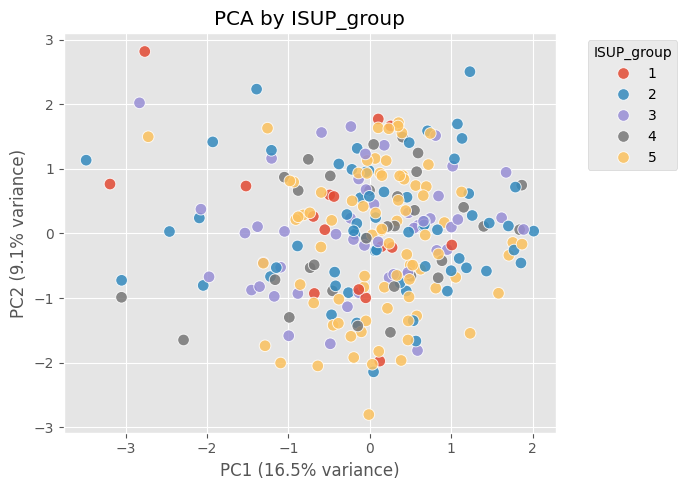

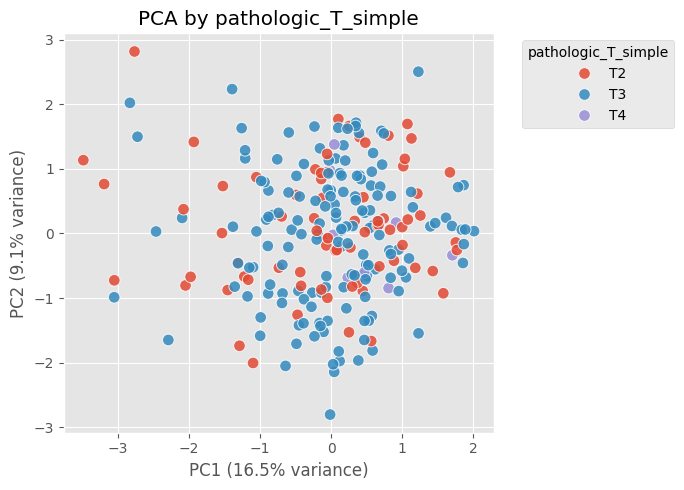

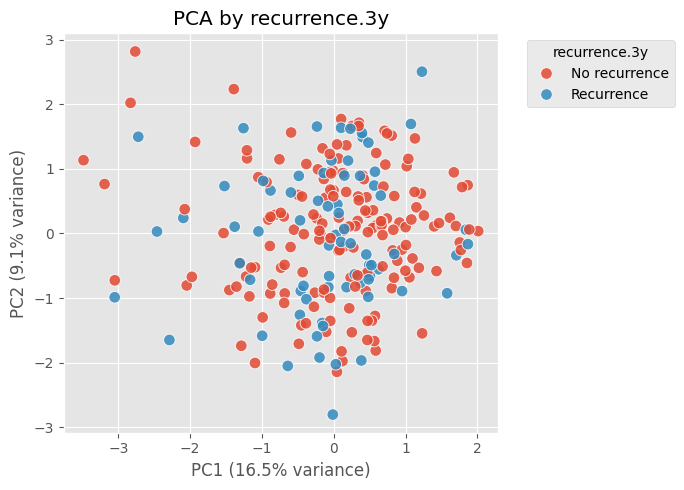

In [ ]:
# Percentage of explained variance
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# Function to plot
def plot_pca(pca_df, color_var):
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=color_var,
        s=70,
        alpha=0.85
    )

    plt.xlabel(f"PC1 ({pc1_var:.1f}% variance)")
    plt.ylabel(f"PC2 ({pc2_var:.1f}% variance)")
    plt.title(f"PCA by {color_var}")
    plt.legend(title=color_var, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plt.style.use("ggplot")

plot_pca(pca_df, "ISUP_group")
plot_pca(pca_df, "pathologic_T_simple")
plot_pca(pca_df, "recurrence.3y")

# Data Partitioning: Creating Training and Test Sets

## Objective and Methodology

A fundamental principle of supervised machine learning is to train a model on one portion of the data and evaluate its performance on a separate, "unseen" portion. This process is essential for two reasons:
1.  **To Prevent Overfitting:** A model is overfit when it learns the training data too well, including its noise, and consequently fails to generalize to new data. Evaluating on an unseen test set provides a realistic measure of this generalization ability.
2.  **To Obtain an Unbiased Performance Estimate:** The performance on the test set serves as an unbiased estimate of how the model would perform in a real-world scenario on new patients.

To create these data subsets, we will first merge the expression (`exp`) and clinical (`pheno`) data into a single comprehensive table. We will then perform a **stratified split**. This method ensures that the original proportion of the outcome classes (e.g., 30% recurrent vs. 70% non-recurrent) is preserved in both the training and test sets, which is critical for preventing bias, especially with imbalanced datasets.

## Your Task: Define the Partitioning Parameters

The outcome of the model evaluation is directly influenced by how the data is split. You will set two key parameters that control this process. Experimenting with these values is a key part of understanding machine learning methodology.

**Modifiable Parameters:**

* `proportion.train`: This value (between 0 and 1) determines the percentage of the data allocated to the **training set**. A common choice is 0.7 or 0.8 (i.e., 70% or 80%).
    * **Impact:** This setting involves a trade-off. A larger training set gives the model more data to learn from, potentially creating a more robust model. However, this leaves a smaller test set, making the final performance evaluation less reliable (i.e., it will have higher variance).
* `set.seed(value)`: This function initializes the random number generator with a specific integer. Since the data split involves random sampling, setting a seed ensures that the *exact same "random" split is generated every time the script is run*.
    * **Impact:** This guarantees **reproducibility**. If you change the seed value (e.g., to `456`), you will generate a different, but still reproducible, partition. This allows you to investigate how sensitive your model's performance is to the specific samples chosen for training versus testing. For a given experiment, keep the seed constant.

**Action:** Set your desired values for `proportion.train` and `set.seed` in the following chunk, then run the code to partition the data.

Also, for clarity and compatibility with R's modeling functions, we rename our outcome column to the generic name `Class` and convert it to a `factor` data type. This explicitly defines it as the categorical target we aim to predict.

In [ ]:
proportion_train = 0.7
random_seed = 42

# Expression and phenotype features
gene_features = exp_filtered.columns.tolist()

# Merge by index
table = exp_filtered.merge(pheno_table, left_index=True, right_index=True)

# Original response variable
y_original = table["recurrence.3y"]

# Encode recurrence.3y


label_encoder = LabelEncoder()

table["Class"] = label_encoder.fit_transform(y_original)

# Check encoding
label_mapping = pd.DataFrame({
    "original_label": label_encoder.classes_,
    "encoded_label": range(len(label_encoder.classes_))
})

display(label_mapping)


,original_label,encoded_label
0,No recurrence,0
1,Recurrence,1


In [ ]:
# Stratified train/test split
table_training, table_testing = train_test_split(
    table,
    train_size=proportion_train,
    random_state=random_seed,
    stratify=table["Class"]
)

# Check class proportions
print("Training class proportions:")
print(table_training["Class"].value_counts(normalize=True))

print("\nTesting class proportions:")
print(table_testing["Class"].value_counts(normalize=True))

Training class proportions:
Class
0    0.705882
1    0.294118
Name: proportion, dtype: float64

Testing class proportions:
Class
0    0.69863
1    0.30137
Name: proportion, dtype: float64


# Feature Selection: Reducing the Number of Genes

In high-dimensional datasets like genomics, we have many more features (genes) than samples. This "curse of dimensionality" can lead to model overfitting and poor performance. The goal of this step is to select a smaller, more informative subset of genes.

Your task is to choose **both** a selection method and the number of genes (`n.genes`) to use. This choice is a critical part of the experimental design and will profoundly influence your model's results.

* **`num_genes = 200`**: This parameter sets the exact number of genes that will be selected and used to train the model. The optimal number is data-dependent and is a key parameter to evaluate.

Below are four different criteria for selecting your `n.genes`. You must choose one method for your analysis.

1.  **Random Selection**:
    * **Rationale**: This is a baseline or control method. It assumes no gene is more important than another and serves as a benchmark to compare against more intelligent methods.

2.  **Highest Variance**:
    * **Rationale**: This method selects genes that show the most variation across the samples in the training set. The assumption is that genes with higher variability are more likely to contain information that differentiates the classes.

3.  **Bibliography-Based**:
    * **Rationale**: This method uses domain knowledge. It selects genes that have been previously identified in scientific literature as being relevant to the condition being studied (e.g., prostate cancer).

4.  **Differential Gene Expression (DGE)**:
    * **Rationale**: This is a powerful statistical approach. It identifies the genes whose expression levels are most significantly different between the classes (e.g., recurrent vs. non-recurrent). It selects the genes most statistically associated with the outcome.


In [8]:
num_genes = 200

Method 1: Random Selection (Baseline)

In [ ]:
np.random.seed(random_seed)
random_genes = np.random.choice(exp.columns, size=num_genes, replace=False).tolist()

Method 2: Highest Variance

In [ ]:
gene_variances = table_training[gene_features].var(axis=0)
top_var_genes_sorted = gene_variances.sort_values(ascending=False).index.tolist()
top_var_genes = top_var_genes_sorted[:num_genes]

Method 3: Bibliography-Based Selection

In [9]:
with open("Data/genes_cancer_prostata_bibliografia.txt", "r") as file:
    bibliography_genes = file.read().splitlines()

# Assumes the list is already pre-ranked
bibliography_genes = bibliography_genes[:num_genes]

Method 4: Differential Gene Expression (DGE)

We will use a Wilcoxon rank-sum (Mann-Whitney U) test, where Null and Alternative hyphotesis are defined as:

- $H_0$: The gene expression values in the two groups (recurrent and non-recurrent) come from the same distribution.
- $H_1$: The gene expression values in the two groups come from different distributions.

Small p-values (e.g. $p<0.05$ rejects $H_o$

In [ ]:
from scipy.stats import mannwhitneyu

def calculate_p_values(expression_data, labels):
    p_values = {}

    for gene in expression_data.columns:
        group_values = [
            expression_data.loc[labels == group, gene].dropna()
            for group in labels.unique()
        ]

        test_result = mannwhitneyu(
            group_values[0],
            group_values[1],
            alternative="two-sided"
        )
        # Calculates a p-value for each gene based on differential expression between two classes
        p_values[gene] = test_result.pvalue

    return pd.Series(p_values)

In [ ]:
p_values = calculate_p_values(
    table_training[gene_features],
    table_training["Class"]
)

In [ ]:
# Create a DataFrame with the results and rank genes by lowest p-value
ranked_DGE_genes = (
    pd.DataFrame({
        "Gene": p_values.index,
        "PValue": p_values.values
    })
    .sort_values("PValue")
    .reset_index(drop=True)
)

# Select the first num_genes with the lowest p-values
top_DGE_genes = ranked_DGE_genes.head(num_genes)["Gene"].tolist()

## Select a subset of genes to use
Select of the previusly generated subset of genes to use as imput for ML models (`random.genes`, `top_DGE_genes` , `bibliography_genes`, `top_var_genes`)

You can change the subset and compare the results...

In [ ]:
# SELECT
genes_to_use = top_DGE_genes
#genes_to_use = bibliography_genes
#genes_to_use = top_var_genes
#genes_to_use = gene_features  # Use all genes for the model

## Create tables for training and validation
At first we will only use the genes as features. **We could consider also use phenotipic data**.

In [ ]:
X_train = table_training[genes_to_use]
y_train = table_training["Class"]

X_test = table_testing[genes_to_use]
y_test = table_testing["Class"]

In [ ]:
# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=random_seed
)

# Models
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, class_weight="balanced"))
    ]),

    "RF": RandomForestClassifier(
        random_state=random_seed, class_weight="balanced"
    ),

    "LOGREG": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
}


Scoring metrics:
- Accuracy: The proportion of correctly classified samples among all samples. It measures the overall classification performance but can be misleading when classes are imbalanced.
- Cohen's Kappa: A measure of agreement between predicted and true labels that accounts for **agreement occurring by chance**. Values range from -1 to 1, where 1 indicates perfect agreement, 0 indicates chance-level agreement, and negative values indicate worse-than-chance agreement.

In [ ]:
# Scoring metrics
scoring = {
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score)
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "Accuracy_mean": scores["test_accuracy"].mean(),
        "Accuracy_sd": scores["test_accuracy"].std(),
        "Kappa_mean": scores["test_kappa"].mean(),
        "Kappa_sd": scores["test_kappa"].std()
    }

metrics_summary_accuracy_kappa = pd.DataFrame(cv_results).T

display(metrics_summary_accuracy_kappa.round(3))

,Accuracy_mean,Accuracy_sd,Kappa_mean,Kappa_sd
KNN,0.753,0.058,0.417,0.111
SVM,0.747,0.098,0.445,0.199
RF,0.753,0.066,0.347,0.150
LOGREG,0.712,0.080,0.326,0.152


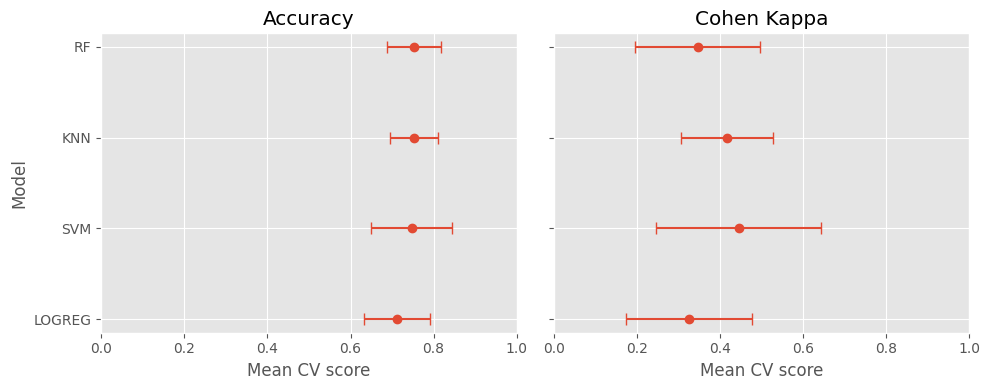

In [ ]:
plt.style.use("ggplot")

metrics_to_plot = {
    "Accuracy": ("Accuracy_mean", "Accuracy_sd"),
    "Cohen Kappa": ("Kappa_mean", "Kappa_sd")
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharey=True
)

plot_data = metrics_summary_accuracy_kappa.copy()
plot_data["Model"] = plot_data.index

for ax, (metric_name, (mean_col, sd_col)) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(mean_col)

    ax.errorbar(
        x=data[mean_col],
        y=data["Model"],
        xerr=data[sd_col],
        fmt="o",
        capsize=4
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Mean CV score")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Model")

plt.tight_layout()
plt.show()

## Training for ROC (AUC)
Following our initial assessment, we now focus on training and comparing the models using Receiver Operating Characteristic (ROC) curves and their Area Under the Curve (AUC). This metric is particularly valuable for evaluating classifiers, especially when dealing with imbalanced datasets, as it provides a comprehensive measure of a model's ability to distinguish between classes across all possible classification thresholds. Unlike accuracy, AUC is less susceptible to misleading results caused by a disproportionate number of samples in one class.

In [ ]:
for encoded_label, original_label in enumerate(label_encoder.classes_):
    print(f"{encoded_label} = {original_label}")

0 = No recurrence
1 = Recurrence


In [ ]:

# recurrence = 1 was encoded as 1; this is the positive class
positive_class = 1
negative_class = 0

# Sensitivity: ability to detect Recurrence
sensitivity_scorer = make_scorer(
    recall_score,
    pos_label=positive_class
)

# Specificity: ability to detect No_recurrence
specificity_scorer = make_scorer(
    recall_score,
    pos_label=negative_class
)

# Cohen's Kappa measures how well predicted labels agree with true labels, correcting for chance agreement.
# A value close to 1 indicates high agreement, while 0 indicates performance equivalent to chance.

scoring = {
    "roc_auc": "roc_auc",
    "sensitivity": sensitivity_scorer,
    "specificity": specificity_scorer
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "ROC_AUC_mean": scores["test_roc_auc"].mean(),
        "ROC_AUC_sd": scores["test_roc_auc"].std(),
        "Sensitivity_mean": scores["test_sensitivity"].mean(),
        "Sensitivity_sd": scores["test_sensitivity"].std(),
        "Specificity_mean": scores["test_specificity"].mean(),
        "Specificity_sd": scores["test_specificity"].std()
    }

metrics_summary_roc = pd.DataFrame(cv_results).T

display(metrics_summary_roc)

,ROC_AUC_mean,ROC_AUC_sd,Sensitivity_mean,Sensitivity_sd,Specificity_mean,Specificity_sd
KNN,0.772083,0.066178,0.60,0.063246,0.816667,0.085797
SVM,0.825833,0.102483,0.72,0.116619,0.758333,0.092796
RF,0.802500,0.098666,0.42,0.116619,0.891667,0.089753
LOGREG,0.757500,0.107639,0.54,0.048990,0.783333,0.096465


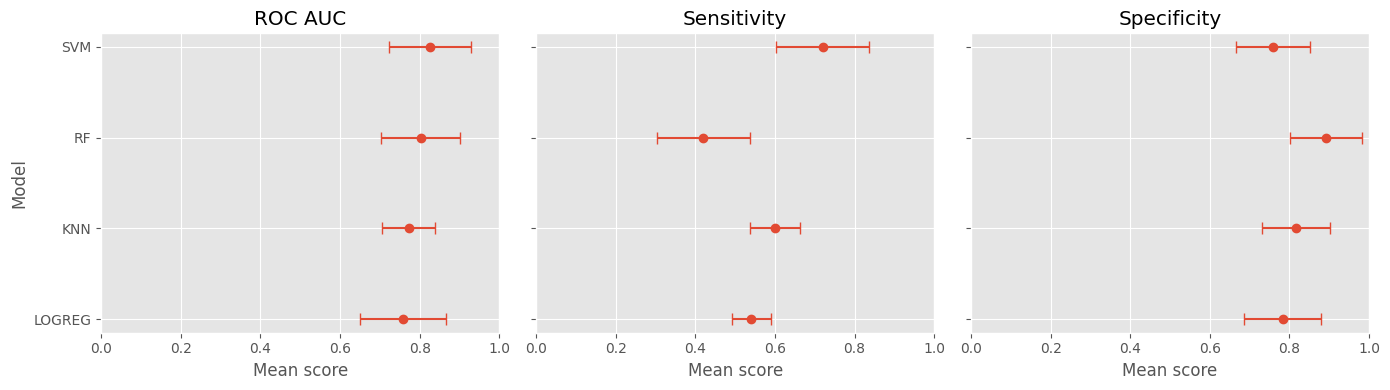

In [ ]:
plt.style.use("ggplot")

metrics_to_plot = {
    "ROC AUC": ("ROC_AUC_mean", "ROC_AUC_sd"),
    "Sensitivity": ("Sensitivity_mean", "Sensitivity_sd"),
    "Specificity": ("Specificity_mean", "Specificity_sd")
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4),
    sharey=True
)

plot_data = metrics_summary_roc.copy()
plot_data["Model"] = plot_data.index

for ax, (metric_name, (mean_col, sd_col)) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(mean_col)

    ax.errorbar(
        x=data[mean_col],
        y=data["Model"],
        xerr=data[sd_col],
        fmt="o",
        capsize=4
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Mean score")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Model")

plt.tight_layout()
plt.show()

# Model Evaluation on Test Data and Comparison with Training and Validation
Following cross-validation, we now evaluate the trained models on the independent test set to obtain an unbiased estimate of their real-world performance. This step is crucial to assess generalization and detect overfitting.

Steps:
1. Predict on Test Data: Use each trained model (KNN, SVM, RF, LogReg) to predict the class labels for the samples in the table.testing dataset.
2. Calculate Performance Metrics: Compute key metrics such as Accuracy, AUC, Sensitivity, and Specificity based on the test set predictions and the true labels.
3. Compare with Cross-Validation Results: Compare the test set performance metrics with the average performance obtained during the 5-fold cross-validation on the training set.
4. Overfitting Indication: A substantial decrease in performance on the test set compared to the training set suggests overfitting.
Visualize Comparison: Present the comparison of training (cross-validated) and test set performance metrics (e.g., AUC) using a plot to visually assess the degree of generalization for each model.

This process provides a realistic assessment of the models' predictive capabilities on new, unseen data.

In [ ]:
performance_summary_roc = {}

positive_class = 1
negative_class = 0

for model_name, model in models.items():
    # Train the model using the full training set
    model.fit(X_train, y_train)

    # Class predictions
    predictions_class = model.predict(X_test)

    # Probability predictions
    predictions_prob = model.predict_proba(X_test)

    # Probability of the positive class
    positive_class_index = list(model.classes_).index(positive_class)
    predictions_prob_positive = predictions_prob[:, positive_class_index]

    # Metrics
    auc_value = roc_auc_score(y_test, predictions_prob_positive)
    accuracy = accuracy_score(y_test, predictions_class)
    kappa = cohen_kappa_score(y_test, predictions_class)

    sensitivity = recall_score(
        y_test,
        predictions_class,
        pos_label=positive_class
    )

    specificity = recall_score(
        y_test,
        predictions_class,
        pos_label=negative_class
    )

    performance_summary_roc[model_name] = {
        "AUC": auc_value,
        "Accuracy": accuracy,
        "Kappa": kappa,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    }

performance_summary_roc = pd.DataFrame(performance_summary_roc)

display(performance_summary_roc.round(3))

,KNN,SVM,RF,LOGREG
AUC,0.696,0.681,0.771,0.619
Accuracy,0.658,0.644,0.740,0.644
Kappa,0.236,0.284,0.339,0.196
Sensitivity,0.545,0.727,0.455,0.500
Specificity,0.706,0.608,0.863,0.706


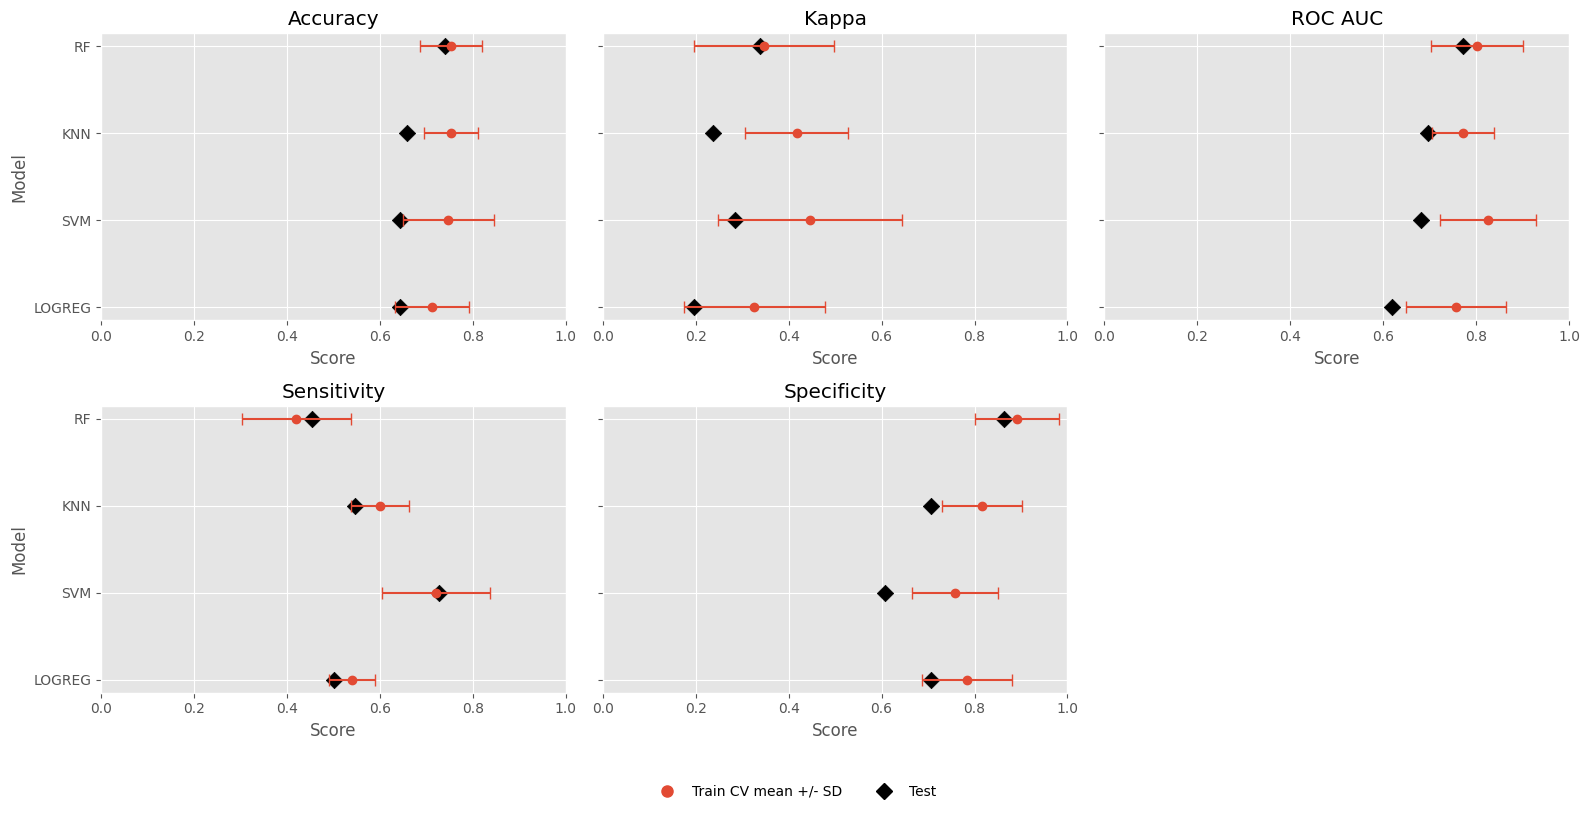

In [ ]:
from matplotlib.lines import Line2D

plt.style.use("ggplot")

# Join training/CV results
training_summary = metrics_summary_accuracy_kappa.join(metrics_summary_roc)

# Test: performance_summary_roc has metrics as rows and models as columns
test_summary = performance_summary_roc.T.copy()

metrics_to_plot = {
    "Accuracy": {
        "cv_mean": "Accuracy_mean",
        "cv_sd": "Accuracy_sd",
        "test": "Accuracy"
    },
    "Kappa": {
        "cv_mean": "Kappa_mean",
        "cv_sd": "Kappa_sd",
        "test": "Kappa"
    },
    "ROC AUC": {
        "cv_mean": "ROC_AUC_mean",
        "cv_sd": "ROC_AUC_sd",
        "test": "AUC"
    },
    "Sensitivity": {
        "cv_mean": "Sensitivity_mean",
        "cv_sd": "Sensitivity_sd",
        "test": "Sensitivity"
    },
    "Specificity": {
        "cv_mean": "Specificity_mean",
        "cv_sd": "Specificity_sd",
        "test": "Specificity"
    }
}

plot_data = training_summary.copy()
plot_data["Model"] = plot_data.index

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8),
    sharey=True
)

axes = axes.flatten()

for ax, (metric_name, cols) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(cols["cv_mean"]).copy()

    # Train / CV
    ax.errorbar(
        x=data[cols["cv_mean"]],
        y=data["Model"],
        xerr=data[cols["cv_sd"]],
        fmt="o",
        capsize=4,
        label="Train CV mean +/- SD"
    )

    # Test
    test_values = test_summary.loc[data["Model"], cols["test"]]

    ax.scatter(
        test_values,
        data["Model"],
        marker="D",
        s=70,
        color="black",
        label="Test"
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Score")
    ax.set_xlim(0, 1)
    #ax.legend(loc="lower right")

axes[0].set_ylabel("Model")
axes[3].set_ylabel("Model")

# Turn off the empty panel, because there are 5 metrics and the grid has 6 slots
axes[-1].axis("off")

#---
legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        #color="tab:blue",
        label="Train CV mean +/- SD",
        linestyle="None",
        markersize=8
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="black",
        label="Test",
        linestyle="None",
        markersize=8
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


#---

# Feature Importance and Refinement
## Feature Importance with Random Forest

This section quantifies the **relative importance of each gene** within our trained Random Forest model. Understanding feature importance is crucial for two reasons:

1.  **Biological Insight:** It helps identify genes that are most influential in predicting biochemical recurrence, potentially revealing underlying biological mechanisms.
2.  **Feature Selection:** This ranking provides a data-driven approach to selecting a refined subset of features for simpler, potentially more robust models.

We will visualize these importance scores to clearly identify the top-contributing genes.

In [ ]:
rf_model = models["RF"]

# Train Random Forest using the training data
rf_model.fit(X_train, y_train)

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Overall": rf_model.feature_importances_
})

importance["Overall_scaled"] = (
    100 * importance["Overall"] / importance["Overall"].max()
)

display(
    importance
    .sort_values("Overall_scaled", ascending=False)
    .head()
)

,Feature,Overall,Overall_scaled
2,DONSON,0.031120,100.000000
0,ACCN4,0.026542,85.291300
117,C9orf152,0.017968,57.739234
13,CNIH2,0.016179,51.989072
16,EME1,0.015334,49.273565


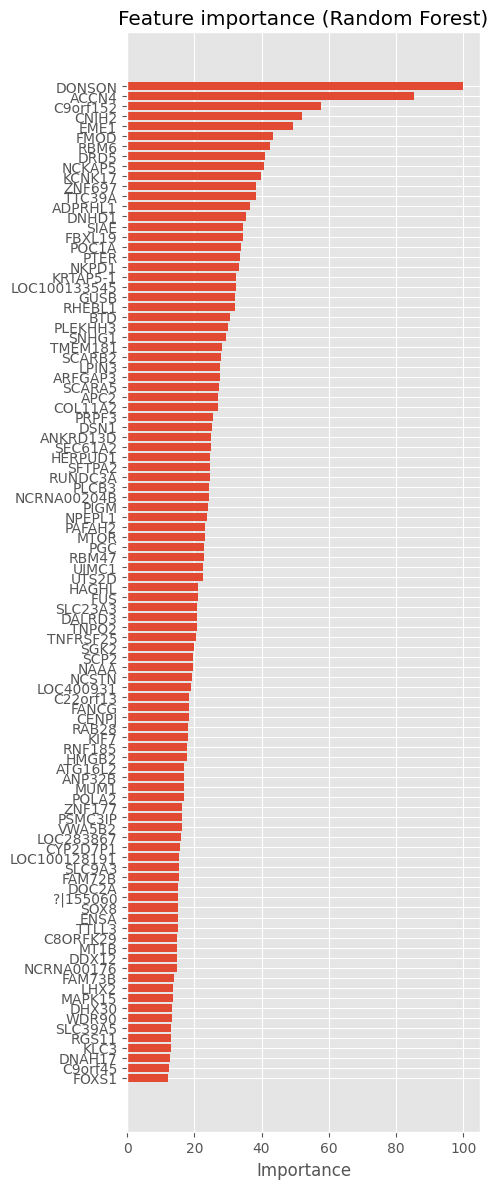

In [ ]:
top_n = 100

importance_plot = (
    importance
    .sort_values("Overall_scaled", ascending=False)
    .head(top_n)
    .sort_values("Overall_scaled")
)

plt.figure(figsize=(5, 12))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Overall_scaled"]
)

plt.xlabel("Importance")
plt.title("Feature importance (Random Forest)")
plt.tight_layout()
plt.show()

## Training and testing all models with Top-K Features

This section directly compares the performance of **all models trained on the full set of genes** (or the initial feature-selected set) against the **models re-trained using only the top `k` most important features**.

The goal is to determine if a simpler model, built with a reduced but highly informative feature set, can achieve comparable or even superior predictive power, thus validating our feature selection strategy.

In [ ]:
# Number of top-ranked variables to use
k = 30  # change this value as needed

# Select the k most important variables from the importance DataFrame
top_k_rf_features = (
    importance
    .sort_values("Overall", ascending=False)
    .head(k)["Feature"]
    .tolist()
)

print(top_k_rf_features)

['DONSON', 'ACCN4', 'C9orf152', 'CNIH2', 'EME1', 'FMOD', 'RBM6', 'DRD5', 'NCKAP5', 'KCNK17', 'ZNF697', 'TTC39A', 'ADPRHL1', 'DNHD1', 'SIAE', 'FBXL19', 'POC1A', 'PTER', 'NKPD1', 'KRTAP5-1', 'LOC100133545', 'GUSB', 'RHEBL1', 'BTD', 'PLEKHH3', 'SNHG1', 'TMEM181', 'SCARB2', 'LPIN3', 'ARFGAP3']


In [ ]:
X_train_rf_top_k = X_train[top_k_rf_features].copy()
X_test_rf_top_k = X_test[top_k_rf_features].copy()

In [ ]:
# Scoring metrics
scoring = {
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score),
    "roc_auc": "roc_auc",
    "sensitivity": sensitivity_scorer,
    "specificity": specificity_scorer
}

cv_results_topk = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results_topk[name] = {
        "Accuracy_mean": scores["test_accuracy"].mean(),
        "Accuracy_sd": scores["test_accuracy"].std(),
        "Kappa_mean": scores["test_kappa"].mean(),
        "Kappa_sd": scores["test_kappa"].std(),
        "ROC_AUC_mean": scores["test_roc_auc"].mean(),
        "ROC_AUC_sd": scores["test_roc_auc"].std(),
        "Sensitivity_mean": scores["test_sensitivity"].mean(),
        "Sensitivity_sd": scores["test_sensitivity"].std(),
        "Specificity_mean": scores["test_specificity"].mean(),
        "Specificity_sd": scores["test_specificity"].std()
    }

metrics_summary_topk = pd.DataFrame(cv_results_topk).T

display(metrics_summary_topk.round(3))

,Accuracy_mean,Accuracy_sd,Kappa_mean,Kappa_sd,ROC_AUC_mean,ROC_AUC_sd,Sensitivity_mean,Sensitivity_sd,Specificity_mean,Specificity_sd
KNN,0.753,0.058,0.417,0.111,0.772,0.066,0.60,0.063,0.817,0.086
SVM,0.747,0.098,0.445,0.199,0.826,0.102,0.72,0.117,0.758,0.093
RF,0.753,0.066,0.347,0.150,0.802,0.099,0.42,0.117,0.892,0.090
LOGREG,0.712,0.080,0.326,0.152,0.758,0.108,0.54,0.049,0.783,0.096


In [ ]:
performance_summary_topk = {}

positive_class = 1
negative_class = 0

for model_name, model in models.items():
    # Train model
    model.fit(X_train_rf_top_k, y_train)

    # Class predictions
    predictions_class = model.predict(X_test_rf_top_k)

    # Probability predictions
    predictions_prob = model.predict_proba(X_test_rf_top_k)

    # Probability of the positive class
    positive_class_index = list(model.classes_).index(positive_class)
    predictions_prob_positive = predictions_prob[:, positive_class_index]

    # Metrics
    auc_value = roc_auc_score(y_test, predictions_prob_positive)
    accuracy = accuracy_score(y_test, predictions_class)
    kappa = cohen_kappa_score(y_test, predictions_class)

    sensitivity = recall_score(
        y_test,
        predictions_class,
        pos_label=positive_class
    )

    specificity = recall_score(
        y_test,
        predictions_class,
        pos_label=negative_class
    )

    performance_summary_topk[model_name] = {
        "AUC": auc_value,
        "Accuracy": accuracy,
        "Kappa": kappa,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    }

performance_summary_topk = pd.DataFrame(performance_summary_topk)

display(performance_summary_topk.round(3))

,KNN,SVM,RF,LOGREG
AUC,0.680,0.684,0.725,0.684
Accuracy,0.644,0.630,0.781,0.603
Kappa,0.233,0.280,0.436,0.192
Sensitivity,0.591,0.773,0.500,0.636
Specificity,0.667,0.569,0.902,0.588


Predict test data

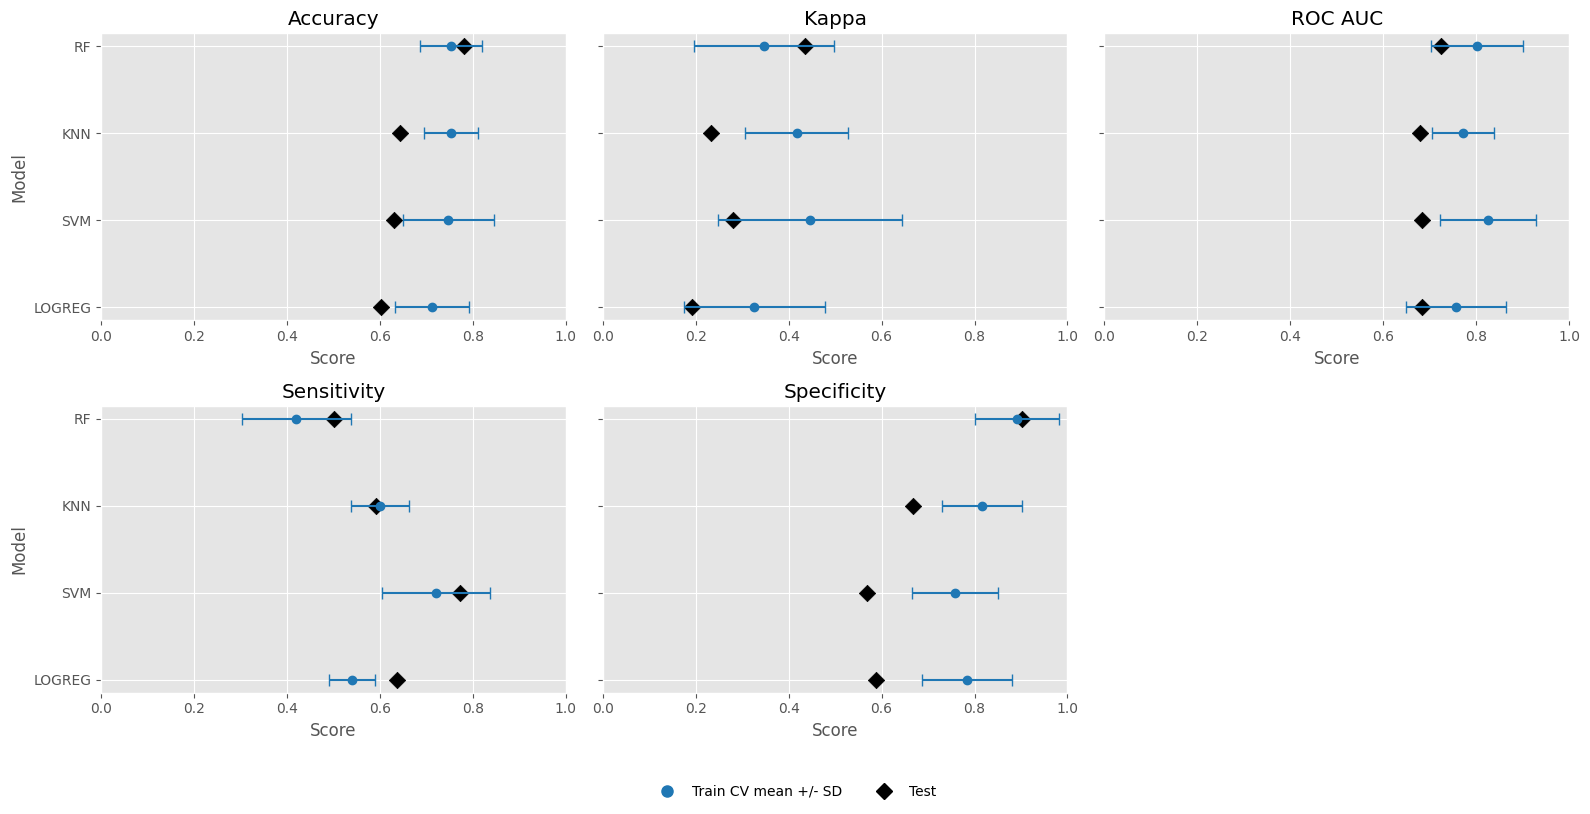

In [ ]:
from matplotlib.lines import Line2D

plt.style.use("ggplot")

# Join training/CV results
training_summary = metrics_summary_topk.copy()

# Test: performance_summary_topk has metrics as rows and models as columns
test_summary = performance_summary_topk.T.copy()

metrics_to_plot = {
    "Accuracy": {
        "cv_mean": "Accuracy_mean",
        "cv_sd": "Accuracy_sd",
        "test": "Accuracy"
    },
    "Kappa": {
        "cv_mean": "Kappa_mean",
        "cv_sd": "Kappa_sd",
        "test": "Kappa"
    },
    "ROC AUC": {
        "cv_mean": "ROC_AUC_mean",
        "cv_sd": "ROC_AUC_sd",
        "test": "AUC"
    },
    "Sensitivity": {
        "cv_mean": "Sensitivity_mean",
        "cv_sd": "Sensitivity_sd",
        "test": "Sensitivity"
    },
    "Specificity": {
        "cv_mean": "Specificity_mean",
        "cv_sd": "Specificity_sd",
        "test": "Specificity"
    }
}

plot_data["Model"] = training_summary.index

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8),
    sharey=True
)

axes = axes.flatten()

for ax, (metric_name, cols) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(cols["cv_mean"]).copy()

    # Train / CV
    ax.errorbar(
        x=data[cols["cv_mean"]],
        y=data["Model"],
        xerr=data[cols["cv_sd"]],
        fmt="o",
        capsize=4,
        color="tab:blue",
        label="Train CV mean +/- SD"
    )

    # Test
    test_values = test_summary.loc[data["Model"], cols["test"]]

    ax.scatter(
        test_values,
        data["Model"],
        marker="D",
        s=70,
        color="black",
        label="Test"
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Score")
    ax.set_xlim(0, 1)
    #ax.legend(loc="lower right")

axes[0].set_ylabel("Model")
axes[3].set_ylabel("Model")

# Turn off the empty panel, because there are 5 metrics and the grid has 6 slots
axes[-1].axis("off")

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="tab:blue",
        label="Train CV mean +/- SD",
        linestyle="None",
        markersize=8
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="black",
        label="Test",
        linestyle="None",
        markersize=8
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

#plt.tight_layout()
#plt.show()